# Final test: 2026 anime

Evaluates the saved pipeline on anime released in 2026, a year the model never saw
while training and that was not used to take any decision.

Needs `data/test/test_clean.csv` (`clean.ju.py` with `SPLIT=test`) and
`model/pipe.joblib` (`train.ju.py`).

**Limits of this test**: it only has 298 entries, all from the same year and all
already finished, so the scores here do not necessarily reflect accurately what the
model can do.

## Setup

In [1]:
import pandas as pd
import joblib
import sys
# the saved pipeline needs anime_transformers.py, which is in the root of the repo
sys.path.append("..")

In [2]:
df = pd.read_csv("../data/test/test_clean.csv", encoding="utf-8")

In [3]:
label = df.columns.str.contains("mean_score")

X_test = df.loc[:, ~label]
y_test = df.loc[:, label]
# from a one column DataFrame to a Series
y_test = y_test.squeeze()

model = joblib.load("../model/pipe.joblib")

## Predictions

In [4]:
pred = model.predict(X_test)

In [5]:
# difference > 0: the real score was higher than the predicted one
comparison = pd.DataFrame({
    "real": y_test, "predicted": pred, "difference": y_test - pred
})

## Scores

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, pred)

# MSE, RMSE and MAE, the last two are in score points (0-100)
print(mse)
print(rmse)
print(mae)

52.93078227259157
7.275354443090149
5.641698788277684


## Distribution of the errors

Histogram of `real - predicted`, with its mean and 1, 2 and 3 standard deviations.
Saved as `images/hist_test.png`.

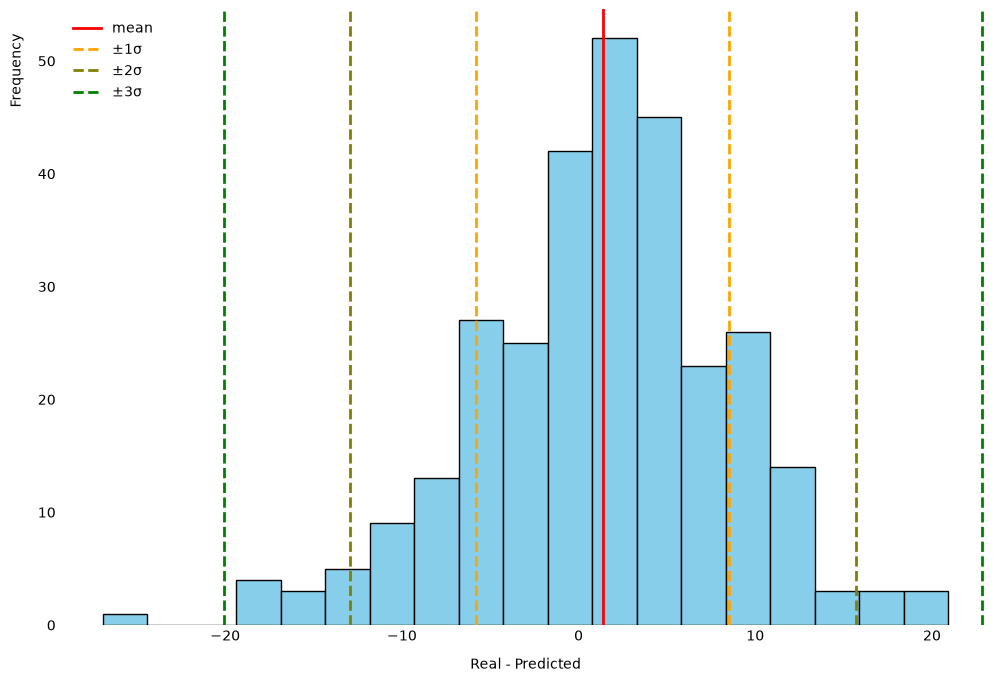

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.hist(comparison["difference"], bins="auto", color="skyblue", edgecolor="black")

mean = comparison["difference"].mean()
std = comparison["difference"].std()

plt.axvline(mean, color="#FF0000", linestyle="-", label="mean", linewidth=2)
plt.axvline(mean + std, color="#FFA500", linestyle="--", label="±1σ", linewidth=2)
plt.axvline(mean - std, color="#FFA500", linestyle="--", linewidth=2)
plt.axvline(mean + 2*std, color="#808000", linestyle="--", label="±2σ", linewidth=2)
plt.axvline(mean - 2*std, color="#808000", linestyle="--", linewidth=2)
plt.axvline(mean + 3*std, color="#008000", linestyle="--", label="±3σ", linewidth=2)
plt.axvline(mean - 3*std, color="#008000", linestyle="--", linewidth=2)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

plt.ylabel("Frequency", labelpad=10, fontsize=10, y=0.9)
plt.xlabel("Real - Predicted", labelpad=10, fontsize=10)

plt.legend(frameon=False, loc="upper left")
plt.show()

## Outliers

Box plot of the same differences, the red points are the outliers.
Saved as `images/box_test.png`.

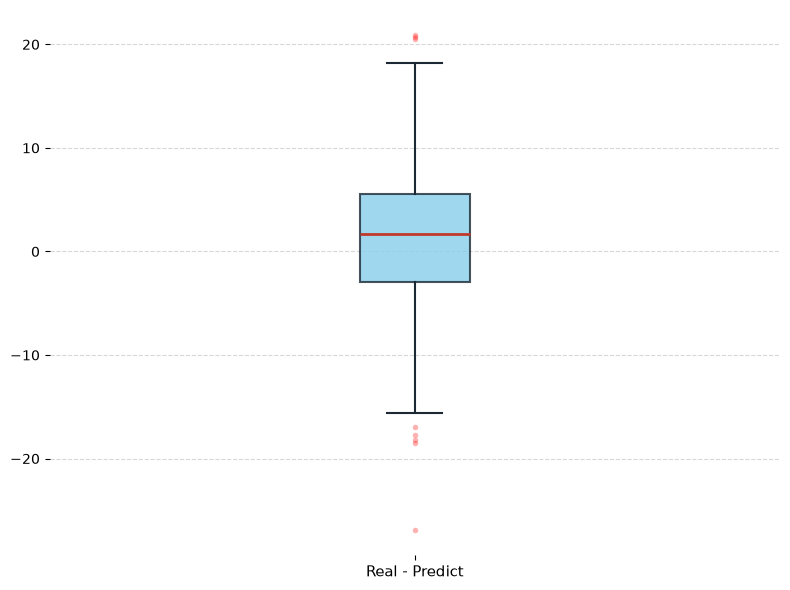

In [10]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

flier_style = dict(
    marker="o",
    markerfacecolor="red",
    markeredgecolor="none",
    markersize=4,
    alpha=0.3,
)

box_style = dict(facecolor="skyblue", edgecolor="#1C2833", alpha=0.8, linewidth=1.5)
median_style = dict(color="#C0392B", linewidth=2)
whisker_style = dict(color="#1C2833", linewidth=1.5)

bp = ax.boxplot(
    comparison["difference"],
    patch_artist=True,
    flierprops=flier_style,
    boxprops=box_style,
    medianprops=median_style,
    whiskerprops=whisker_style,
    capprops=whisker_style,
    orientation="vertical",
)

ax.set_xticklabels(["Real - Predict"], fontsize=11)

for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(False)

ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()